# Amazon Bedrock Unified Converse API

*This notebook demonstrates how to use the Amazon Bedrock **Converse API** and **ConverseStream API** using **Amazon first-party models** (Amazon Nova and Amazon Titan). Adapted from [AWS Samples: 01_converse_api.ipynb](https://github.com/aws-samples/amazon-bedrock-samples/blob/main/introduction-to-bedrock/converse_api/01_converse_api.ipynb).*

---

## What is the Converse API?

Historically, every foundation model provider on Amazon Bedrock required its own custom request/response payload schema:
- Amazon Titan: `inputText` and `textGenerationConfig`
- Amazon Nova: `messages-v1` and `inferenceConfig`
- Anthropic Claude: `anthropic_version`, `messages`, and `max_tokens`
- Cohere: `prompt` and `max_tokens`

The **Converse API** (`bedrock_runtime.converse` and `bedrock_runtime.converse_stream`) standardizes and unifies LLM invocations across **all** foundation models on Amazon Bedrock:

1. **Universal Message Format**: Single, standardized `messages=[{'role': 'user'|'assistant', 'content': [...]}]` structure across all models.
2. **Normalized Inference Parameters**: Consistent `inferenceConfig={'temperature': ..., 'maxTokens': ..., 'topP': ...}`.
3. **Native Multimodal Support**: Uniform content blocks for `text`, `image` (PNG, JPEG, GIF, WEBP), and `document` (PDF, CSV, DOC, DOCX, TXT, HTML, MD).
4. **Built-in System Prompts**: Standardized `system=[{'text': '...'}]` without embedding system directives inside user messages.
5. **Unified Safeguards & Tools**: Direct integration with Bedrock Guardrails (`guardrailConfig`) and tool use / function calling (`toolConfig`).
6. **Standardized Telemetry**: Uniform response structure (`output.message.content`, `stopReason`, `usage.inputTokens`, `usage.outputTokens`, `metrics.latencyMs`).


## Supported Amazon Models in this Notebook

This notebook focuses strictly on Amazon's native first-party models:

| Model Family | Model Name | Model ID / Inference Profile | Multimodal Capabilities |
| :--- | :--- | :--- | :--- |
| **Amazon Nova** | Nova Micro | `us.amazon.nova-micro-v1:0` | Text-only, ultra fast & lowest cost |
| **Amazon Nova** | Nova Lite | `us.amazon.nova-lite-v1:0` | Multimodal (Text, Images, Documents), cost-effective |
| **Amazon Nova** | Nova Pro | `us.amazon.nova-pro-v1:0` | Multimodal (Text, Images, Documents), advanced reasoning |
| **Amazon Titan** | Titan Text Express | `amazon.titan-text-express-v1` | Text-only, general text generation |


## 1. Setup & Boto3 Runtime Client Initialization

To use the Converse API, you call `converse` or `converse_stream` on the `bedrock-runtime` client in your target region (`us-east-2`).

### Required Dependencies
```bash
pip install boto3 ipython Pillow
```
*(Note: `Pillow` is optional and only needed if you generate synthetic images in memory. This notebook includes pre-rendered sample assets in `examples/bedrock/` so all cells execute cleanly without external dependencies).*


In [1]:
import boto3
import json
import os
import sys
from botocore.exceptions import ClientError

# Configure target region
REGION = "us-east-2"

bedrock_runtime = boto3.client(service_name="bedrock-runtime", region_name=REGION)

# Amazon models to use across demonstrations
NOVA_LITE = "us.amazon.nova-lite-v1:0"
NOVA_MICRO = "us.amazon.nova-micro-v1:0"
NOVA_PRO = "us.amazon.nova-pro-v1:0"

AMAZON_MODELS = [NOVA_MICRO, NOVA_LITE, NOVA_PRO]

print(f"Bedrock Runtime client initialized for region: {REGION}")
print(f"Available Amazon Models: {AMAZON_MODELS}")


Bedrock Runtime client initialized for region: us-east-2
Available Amazon Models: ['us.amazon.nova-micro-v1:0', 'us.amazon.nova-lite-v1:0', 'us.amazon.nova-pro-v1:0']


## 2. One-Shot Invocations with `Converse`

In one-shot invocation, we pass a single prompt message and receive the standardized response.
Notice how clean and readable the syntax is compared to legacy provider-specific JSON payloads:


In [5]:
def invoke_bedrock_converse(
    client,
    model_id: str,
    prompt: str,
    max_tokens: int = 500,
    temperature: float = 0.7,
    top_p: float = 0.9
):
    """
    Invokes a foundation model using the unified Bedrock Converse API.
    """
    try:
        response = client.converse(
            modelId=model_id,
            messages=[
                {
                    "role": "user",
                    "content": [{"text": prompt}]
                }
            ],
            inferenceConfig={
                "maxTokens": max_tokens,
                "temperature": temperature,
                "topP": top_p
            }
        )
        return response
    except ClientError as e:
        print(f"Error invoking model {model_id}: {e}")
        raise e

# Test one-shot invocation with Amazon Nova Lite
prompt = "Explain the difference between synchronous and asynchronous APIs in 2 concise sentences."
print(f"Prompt: {prompt}\n")

response = invoke_bedrock_converse(bedrock_runtime, NOVA_LITE, prompt)

# Access standardized output message
output_text = response["output"]["message"]["content"][0]["text"]
print(f"--- Response from {NOVA_LITE} ---")
print(output_text)

# Access standardized usage and metrics
usage = response["usage"]
metrics = response.get("metrics", {})
print(f"\nInput Tokens:  {usage['inputTokens']}")
print(f"Output Tokens: {usage['outputTokens']}")
print(f"Total Tokens:  {usage['totalTokens']}")
print(f"Latency:       {metrics.get('latencyMs', 'N/A')} ms")
print(f"Stop Reason:   {response.get('stopReason')}")


Prompt: Explain the difference between synchronous and asynchronous APIs in 2 concise sentences.

--- Response from us.amazon.nova-lite-v1:0 ---
Synchronous APIs block execution until the operation completes, providing immediate results, whereas asynchronous APIs allow execution to continue without waiting, typically using callbacks, promises, or async/await to handle the result.

Input Tokens:  14
Output Tokens: 41
Total Tokens:  55
Latency:       518 ms
Stop Reason:   end_turn


## 3. Real-Time Streaming with `ConverseStream`

The `converse_stream` API unifies streaming across models.
Chunks arrive as standardized events:
- `messageStart`: Initial metadata
- `contentBlockDelta`: Individual text chunks (`event['contentBlockDelta']['delta']['text']`)
- `messageStop`: Stop reason
- `metadata`: Token usage and metrics


In [6]:
def invoke_bedrock_converse_stream(
    client,
    model_id: str,
    prompt: str,
    max_tokens: int = 400,
    temperature: float = 0.5
):
    """
    Streams responses in real time using the unified converse_stream API.
    """
    response = client.converse_stream(
        modelId=model_id,
        messages=[
            {
                "role": "user",
                "content": [{"text": prompt}]
            }
        ],
        inferenceConfig={
            "maxTokens": max_tokens,
            "temperature": temperature
        }
    )
    
    for event in response.get("stream"):
        if "contentBlockDelta" in event:
            text_chunk = event["contentBlockDelta"].get("delta", {}).get("text", "")
            sys.stdout.write(text_chunk)
            sys.stdout.flush()
    print()

streaming_prompt = "Give 3 best practices for designing scalable cloud architectures with microservices."
print(f"Streaming Prompt: {streaming_prompt}\n")
print(f"--- Streaming from {NOVA_LITE} ---")
invoke_bedrock_converse_stream(bedrock_runtime, NOVA_LITE, streaming_prompt)


Streaming Prompt: Give 3 best practices for designing scalable cloud architectures with microservices.

--- Streaming from us.amazon.nova-lite-v1:0 ---
Designing scalable cloud architectures with microservices involves several best practices to ensure reliability, maintainability, and efficiency. Here are three key practices:

### 1. **API Gateway Implementation**
An API Gateway serves as a single entry point for all client requests, routing them to the appropriate microservices. This practice offers several benefits:

- **Centralized Security**: Implement authentication, authorization, and rate limiting at the gateway to secure access to your microservices.
- **Load Balancing**: Distribute incoming traffic efficiently across microservices to prevent any single service from becoming a bottleneck.
- **Caching**: Use caching to reduce the load on microservices and improve response times for frequently accessed data.
- **Monitoring and Analytics**: Centralize logging, monitoring, and anal

## 4. Multi-Turn Conversation with System Prompts

The Converse API makes building multi-turn conversations intuitive:
- You define a top-level **`system`** prompt to guide personality, role, or constraints.
- As turns progress, append the user message and the returned model message (`response['output']['message']`) to the `messages` list.
- The entire conversation history is passed to preserve context across turns.


In [7]:
def run_conversation_turn(client, model_id, system_prompts, messages):
    """
    Executes a single conversational turn, logging token usage and returning response.
    """
    response = client.converse(
        modelId=model_id,
        messages=messages,
        system=system_prompts,
        inferenceConfig={"temperature": 0.5, "maxTokens": 500}
    )
    
    usage = response["usage"]
    print(f"[Turn Tokens - In: {usage['inputTokens']}, Out: {usage['outputTokens']}, Total: {usage['totalTokens']}]")
    return response

# 1. Define system role
system_prompts = [
    {"text": "You are an expert IT cloud advisor. Give concise, direct, and actionable advice."}
]

messages = []

# --- Turn 1 ---
turn_1_user = {"role": "user", "content": [{"text": "What are the top 3 cloud databases for time-series metrics?"}]}
messages.append(turn_1_user)
print("User Turn 1: What are the top 3 cloud databases for time-series metrics?")

resp_1 = run_conversation_turn(bedrock_runtime, NOVA_LITE, system_prompts, messages)
assistant_msg_1 = resp_1["output"]["message"]
messages.append(assistant_msg_1)
print(f"Assistant:\n{assistant_msg_1['content'][0]['text']}\n")

# --- Turn 2 (Context-dependent follow-up) ---
turn_2_user = {"role": "user", "content": [{"text": "Which one of those 3 is fully managed and native to AWS?"}]}
messages.append(turn_2_user)
print("User Turn 2: Which one of those 3 is fully managed and native to AWS?")

resp_2 = run_conversation_turn(bedrock_runtime, NOVA_LITE, system_prompts, messages)
assistant_msg_2 = resp_2["output"]["message"]
messages.append(assistant_msg_2)
print(f"Assistant:\n{assistant_msg_2['content'][0]['text']}\n")

print(f"Conversation complete! Total turns stored in history: {len(messages)}")


User Turn 1: What are the top 3 cloud databases for time-series metrics?
[Turn Tokens - In: 31, Out: 153, Total: 184]
Assistant:
1. **Amazon Timestream**
   - **Pros:** Optimized for time-series data, easy to scale, integrates well with AWS services.
   - **Cons:** Limited features compared to traditional databases, higher cost per query.

2. **Google Cloud Spanner**
   - **Pros:** Horizontally scalable, strong consistency, supports time-series data.
   - **Cons:** Complexity in setup and management, potentially high costs.

3. **Azure Time Series Insights**
   - **Pros:** Built for time-series data visualization, integrates with Azure IoT, easy data exploration.
   - **Cons:** Limited advanced querying capabilities, higher costs for large datasets.

Choose based on your specific needs and existing cloud ecosystem.

User Turn 2: Which one of those 3 is fully managed and native to AWS?
[Turn Tokens - In: 202, Out: 44, Total: 246]
Assistant:
**Amazon Timestream** is fully managed and nat

## 5. Multimodal Conversation with Images using Amazon Nova

**Amazon Nova Lite** and **Amazon Nova Pro** are natively multimodal. The Converse API allows you to attach images directly inside the `content` block:

```python
{
    "image": {
        "format": "png",  # 'png', 'jpeg', 'gif', 'webp'
        "source": {"bytes": image_bytes}
    }
}
```

> [!TIP]
> This cell loads `examples/bedrock/architecture.png` using standard library file operations and `IPython.display.Image` (zero external dependencies). If you wish to dynamically draw or edit images in Python, you can install Pillow (`pip install Pillow`).


Loaded sample architecture diagram from: ../../examples/bedrock/architecture.png (15500 bytes)


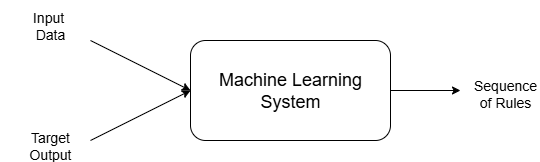

Invoking us.amazon.nova-lite-v1:0 with image content...

--- Amazon Nova Lite Vision Output ---
The diagram illustrates a machine learning system architecture. The key components are:

1. **Input Data**: This is the raw data fed into the system for learning and analysis.
2. **Target Output**: This represents the desired outcome or label that the system aims to predict or classify.
3. **Machine Learning System**: This is the core component where the learning process occurs. It processes the input data and learns to generate a sequence of rules.
4. **Sequence of Rules**: This is the output of the machine learning system, which consists of a set of rules derived from the input data and target output.

The connections in the diagram are:

- **Input Data** is fed into the **Machine Learning System**.
- The **Machine Learning System** processes the input data and learns to generate a **Sequence of Rules**.
- The **Target Output** is used as a reference for the learning process, guiding the s

In [9]:
import io
import os
from IPython.display import display, Image as IPImage

# Look for sample architecture diagram in common relative paths
possible_img_paths = [
    "../../examples/bedrock/architecture.png",
    "../examples/bedrock/architecture.png",
    "examples/bedrock/architecture.png"
]

image_bytes = None
loaded_path = None

for path in possible_img_paths:
    if os.path.exists(path):
        loaded_path = path
        with open(path, "rb") as f:
            image_bytes = f.read()
        print(f"Loaded sample architecture diagram from: {path} ({len(image_bytes)} bytes)")
        break

# Fallback: create synthetic diagram in memory if Pillow is installed
if not image_bytes:
    try:
        from PIL import Image, ImageDraw
        img = Image.new("RGB", (400, 200), color=(240, 244, 248))
        draw = ImageDraw.Draw(img)
        draw.rectangle([30, 60, 160, 140], fill=(66, 133, 244), outline=(20, 60, 140), width=2)
        draw.text((45, 90), "Client App", fill=(255, 255, 255))
        draw.line([(160, 100), (230, 100)], fill=(30, 30, 30), width=3)
        draw.polygon([(240, 100), (230, 95), (230, 105)], fill=(30, 30, 30))
        draw.rectangle([240, 60, 370, 140], fill=(52, 168, 83), outline=(20, 100, 40), width=2)
        draw.text((260, 90), "API Gateway", fill=(255, 255, 255))

        img_byte_arr = io.BytesIO()
        img.save(img_byte_arr, format="PNG")
        image_bytes = img_byte_arr.getvalue()
        print("Created synthetic diagram in memory using PIL.")
    except ImportError:
        print("Pillow not installed. (Run 'pip install Pillow' if you wish to generate images in memory).")

if image_bytes:
    # Display the image in the notebook without requiring PIL
    display(IPImage(data=image_bytes))

    # Send the image + prompt to Amazon Nova Lite via the Converse API
    image_message = {
        "role": "user",
        "content": [
            {"image": {"format": "png", "source": {"bytes": image_bytes}}},
            {"text": "Describe what you see in this architecture diagram. What key components and connections are shown?"}
        ]
    }

    print(f"Invoking {NOVA_LITE} with image content...\n")
    response = bedrock_runtime.converse(
        modelId=NOVA_LITE,
        messages=[image_message],
        inferenceConfig={"maxTokens": 300, "temperature": 0.3}
    )

    print("--- Amazon Nova Lite Vision Output ---")
    print(response["output"]["message"]["content"][0]["text"])
else:
    print("Error: No image source found. Please verify examples/bedrock/architecture.png or install Pillow.")


## 6. Multimodal Conversation with Documents using Amazon Nova

In addition to images, the Converse API natively supports **`document` content blocks** (PDF, CSV, DOC, DOCX, XLS, XLSX, HTML, TXT, MD).

```python
{
    "document": {
        "name": "MeetingNotes",
        "format": "txt",  # or 'pdf', 'csv', 'docx', etc.
        "source": {"bytes": document_bytes}
    }
}
```

Let's pass our existing meeting transcript (`examples/bedrock/Tesla_meeting.txt`) as a native document attachment to Amazon Nova Lite:


In [10]:
import os

# Multi-path search for document attachment
possible_doc_paths = [
    "../../examples/bedrock/Tesla_meeting.txt",
    "../examples/bedrock/Tesla_meeting.txt",
    "examples/bedrock/Tesla_meeting.txt"
]

doc_bytes = None
for path in possible_doc_paths:
    if os.path.exists(path):
        with open(path, "rb") as f:
            doc_bytes = f.read()
        doc_format = "txt"
        doc_name = "TeslaMeetingTranscript"
        print(f"Loaded document from: {path} ({len(doc_bytes)} bytes)")
        break

if not doc_bytes:
    doc_text = """Q3 Executive Highlights
1. Deliveries reached 435,059 vehicles worldwide.
2. Total production reached 430,488 units, up 25% year-over-year.
3. Energy storage reached 4.0 GWh in deployment.
"""
    doc_bytes = doc_text.encode("utf-8")
    doc_format = "txt"
    doc_name = "Highlights"
    print(f"Using built-in sample document ({len(doc_bytes)} bytes)")

# Prepare Converse message with native document content block
document_message = {
    "role": "user",
    "content": [
        {
            "document": {
                "name": doc_name,
                "format": doc_format,
                "source": {"bytes": doc_bytes}
            }
        },
        {"text": "Based on this document, summarize the primary production milestones and metrics in 3 concise bullet points."}
    ]
}

print(f"Invoking {NOVA_LITE} with document content block...\n")
response = bedrock_runtime.converse(
    modelId=NOVA_LITE,
    messages=[document_message],
    inferenceConfig={"maxTokens": 350, "temperature": 0.3}
)

print("--- Amazon Nova Lite Document Analysis ---")
print(response["output"]["message"]["content"][0]["text"])
print("\nUsage:", response.get("usage"))


Loaded document from: ../../examples/bedrock/Tesla_meeting.txt (5567 bytes)
Invoking us.amazon.nova-lite-v1:0 with document content block...

--- Amazon Nova Lite Document Analysis ---
- **Battery Technology**: Tesla's new 4680 cells are in advanced testing stages, showing a 20% increase in range and potential cost reduction. Pilot production is underway in Fremont, with plans for larger-scale production by Q4.
- **Cybertruck Production**: Preparations for the Cybertruck are in full swing, with the exoskeleton design finalized and a new alloy for the body. The primary challenge is scaling the manufacturing process, which is being addressed by leveraging expertise from Fremont and Shanghai factories and new casting machines.
- **Gigafactory Expansion**: The Gigafactory in Austin is on track for production start by next year, which will significantly boost output for both cars and batteries. Additionally, Gigafactory Berlin is nearing completion, with the first Model Ys expected to roll 

## 7. Clean Up & Resource Management

### Resource Lifecycle & Pricing
- **Stateless On-Demand Invocations**: Both `converse` and `converse_stream` are stateless on-demand API calls. They do not provision any dedicated EC2 instances, SageMaker endpoints, or persistent hourly-billed infrastructure.
- **Zero Idle Cost**: You are charged strictly per input/output token (and input image/document bytes processed). Ongoing idle cost is **$0.00**.

### Recommended Cleanup Steps:
1. **Kernel Shutdown**: Shut down the notebook kernel (`Kernel` -> `Shut Down Kernel`) when finished to terminate running threads and free local RAM.
2. **Monitor Cost & Token Usage**: Review tokens and invocation metrics in the [AWS Cost Explorer](https://console.aws.amazon.com/cost-management/home) and Amazon CloudWatch `Bedrock` metrics.

---

## Summary

In this notebook, you learned:
- ✅ How the **Converse API** replaces custom JSON schemas with a universal structured message interface.
- ✅ How to perform one-shot invocations with `converse` using **Amazon Nova** models.
- ✅ How to stream responses in real-time with `converse_stream`.
- ✅ How to manage multi-turn conversational context with `system` prompts.
- ✅ How to pass **images** (`image` content blocks) to Amazon Nova Lite.
- ✅ How to pass **documents** (`document` content blocks) to Amazon Nova Lite for native document analysis.

### Related Notebooks
- [001-Invoke-model.ipynb](001-Invoke-model.ipynb): Low-level `invoke_model` API with Amazon Nova and Titan.
- [002-Streaming-response.ipynb](002-Streaming-response.ipynb): In-depth streaming patterns and event stream lifecycles.
- [003-Guardrails.ipynb](003-Guardrails.ipynb): Attaching content filters, PII masking, and topic filters to Converse calls.
- [004-Knowledge-Base.ipynb](004-Knowledge-Base.ipynb): Retrieval-Augmented Generation (RAG) with Bedrock Knowledge Bases.
